# BASA Stage 2: cue reliance across architectures

One classifier per backbone (ConvNeXt-T, ResNet-50, ViT-B/16, Swin-T) is fine-tuned on intact images,
then the same model is evaluated on test inputs corrupted at test time: COLOR (intact), GRAY, BLUR,
SHUFFLE (8x8 patch permutation) and PHASE (Fourier phase scramble). Grid: 4 backbones x 3 datasets
(Jambi, Nitik, DION) x 3 seeds = 36 runs, about 30 minutes on a Kaggle T4.

Outputs: `cue_reliance_multiarch_raw.csv`, `cue_reliance_multiarch_summary.csv`, `fig_cue_reliance_multiarch.png`.
A run is flagged `converged=False` if its COLOR accuracy is below 3x chance; retention is not interpreted for such runs.


In [1]:
# ============================================================
# M0. CONFIG + UTILITIES (mandiri)
# ============================================================
import os, re, math, time, random, numpy as np, pandas as pd
from PIL import Image
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import (convnext_tiny, ConvNeXt_Tiny_Weights,
                                resnet50,      ResNet50_Weights,
                                vit_b_16,      ViT_B_16_Weights,
                                swin_t,        Swin_T_Weights)

IMG_SIZE   = 224
BATCH      = 32
LR         = 1e-4
EPOCHS     = 10
SEEDS      = [0, 1, 2]
TEST_FRAC  = 0.30
PRETRAINED = True
WORKERS    = 2
OUT_RAW    = "/kaggle/working/cue_reliance_multiarch_raw.csv"

def pick_device():
    if torch.cuda.is_available():
        try:
            _=torch.zeros(8,8,device="cuda")@torch.zeros(8,8,device="cuda"); torch.cuda.synchronize()
            return torch.device("cuda")
        except Exception as e:
            print("[!] GPU tak kompatibel -> CPU.", str(e)[:80])
    return torch.device("cpu")
DEVICE=pick_device(); USE_CUDA=(DEVICE.type=="cuda")
print("Device:", DEVICE, "|", torch.cuda.get_device_name(0) if USE_CUDA else "")

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

# ---- AMP kompatibel lintas versi torch ----
def make_scaler():
    try:    return torch.amp.GradScaler("cuda", enabled=USE_CUDA)
    except Exception: return torch.cuda.amp.GradScaler(enabled=USE_CUDA)
def amp_ctx():
    try:    return torch.amp.autocast("cuda", enabled=USE_CUDA)
    except Exception: return torch.cuda.amp.autocast(enabled=USE_CUDA)

MEAN=[0.485,0.456,0.406]; STD=[0.229,0.224,0.225]

# ---------------- perusak isyarat (hanya dipakai saat TEST) ----------------
class PatchShuffle:
    """Acak tata-letak grid g x g, permutasi TETAP -> hancurkan susunan motif global, jaga tekstur lokal."""
    def __init__(self, g=8, seed=123):
        self.g=g; self.perm=np.random.RandomState(seed).permutation(g*g)
    def __call__(self, t):
        C,H,W=t.shape; g=self.g; ph=H//g; pw=W//g
        t=t[:,:g*ph,:g*pw]
        p=t.unfold(1,ph,ph).unfold(2,pw,pw).contiguous().view(C,g*g,ph,pw)
        p=p[:,self.perm,:,:].view(C,g,g,ph,pw).permute(0,1,3,2,4).contiguous().view(C,g*ph,g*pw)
        return p

class PhaseScramble:
    """Ganti FASE spasial dgn field acak TETAP -> hancurkan kontur/bentuk/motif,
    pertahankan spektrum-amplitudo (statistik tekstur) & rata-rata warna (DC)."""
    def __init__(self, size=IMG_SIZE, seed=123):
        rng=np.random.RandomState(seed)
        ph=rng.uniform(-math.pi, math.pi, size=(size,size)).astype("float32")
        ph[0,0]=0.0
        self.phase=torch.tensor(ph)
    def __call__(self, t):
        C,H,W=t.shape; ph=self.phase[:H,:W]; out=torch.empty_like(t)
        for c in range(C):
            F=torch.fft.fft2(t[c]); out[c]=torch.fft.ifft2(F.abs()*torch.exp(1j*ph)).real
        return out.clamp(0,1)

RS=transforms.Resize((IMG_SIZE,IMG_SIZE))
TRAIN_TF = transforms.Compose([RS, transforms.ToTensor(), transforms.Normalize(MEAN,STD)])
TEST_TF = {
 "COLOR":   transforms.Compose([RS, transforms.ToTensor(), transforms.Normalize(MEAN,STD)]),
 "GRAY":    transforms.Compose([RS, transforms.Grayscale(3), transforms.ToTensor(), transforms.Normalize(MEAN,STD)]),
 "BLUR":    transforms.Compose([RS, transforms.GaussianBlur(21, sigma=8.0), transforms.ToTensor(), transforms.Normalize(MEAN,STD)]),
 "SHUFFLE": transforms.Compose([RS, transforms.ToTensor(), PatchShuffle(8), transforms.Normalize(MEAN,STD)]),
 "PHASE":   transforms.Compose([RS, transforms.ToTensor(), PhaseScramble(IMG_SIZE), transforms.Normalize(MEAN,STD)]),
}
CONDS=list(TEST_TF.keys()); MOTIF_DESTROYERS=["BLUR","SHUFFLE","PHASE"]

# ---------------- arsitektur ----------------
def _convnext(n):
    m=convnext_tiny(weights=ConvNeXt_Tiny_Weights.DEFAULT if PRETRAINED else None)
    m.classifier[2]=nn.Linear(m.classifier[2].in_features,n); return m
def _resnet(n):
    m=resnet50(weights=ResNet50_Weights.DEFAULT if PRETRAINED else None)
    m.fc=nn.Linear(m.fc.in_features,n); return m
def _vit(n):
    m=vit_b_16(weights=ViT_B_16_Weights.DEFAULT if PRETRAINED else None)
    m.heads.head=nn.Linear(m.heads.head.in_features,n); return m
def _swin(n):
    m=swin_t(weights=Swin_T_Weights.DEFAULT if PRETRAINED else None)
    m.head=nn.Linear(m.head.in_features,n); return m

ARCHS      = {"ConvNeXt-T":_convnext, "ResNet-50":_resnet, "ViT-B/16":_vit, "Swin-T":_swin}
ARCH_BATCH = {"ViT-B/16":16}     # ViT paling berat
ARCH_LR    = {}                  # override bila suatu arsitektur gagal konvergen, mis. {"ViT-B/16":3e-5}

# ---------------- dataset in-memory ----------------
class DS(Dataset):
    """Pakai cache uint8 (sudah di-resize) -> tak ada decode JPEG berulang."""
    def __init__(self, df, l2i, tf, cache):
        self.df=df.reset_index(drop=True); self.l2i=l2i; self.tf=tf; self.cache=cache
    def __len__(self): return len(self.df)
    def __getitem__(self,i):
        r=self.df.iloc[i]
        return self.tf(Image.fromarray(self.cache[r["path"]])), self.l2i[r["class_label"]]

def strat_split(df, seed, frac=TEST_FRAC):
    rng=np.random.RandomState(seed); tr,te=[],[]
    for c,g in df.groupby("class_label"):
        idx=g.index.to_numpy(); rng.shuffle(idx); k=max(1,int(round(frac*len(idx))))
        te+=list(idx[:k]); tr+=list(idx[k:])
    return df.loc[tr], df.loc[te]

def _acc(model, loader):
    model.eval(); cor=tot=0
    with torch.no_grad():
        for x,y in loader:
            x,y=x.to(DEVICE,non_blocking=True),y.to(DEVICE,non_blocking=True)
            cor+=(model(x).argmax(1)==y).sum().item(); tot+=y.size(0)
    return 100.0*cor/tot

def run_one(arch, df, seed, cache, epochs=EPOCHS):
    """Latih SATU model pada citra UTUH, lalu uji model yg SAMA di 5 kondisi test."""
    set_seed(seed)
    l2i={c:i for i,c in enumerate(sorted(df.class_label.unique()))}
    tr,te=strat_split(df,seed)
    bs=ARCH_BATCH.get(arch,BATCH); lr=ARCH_LR.get(arch,LR)

    for attempt in range(3):                      # fallback OOM
        try:
            tl=DataLoader(DS(tr,l2i,TRAIN_TF,cache),batch_size=bs,shuffle=True,
                          num_workers=WORKERS,pin_memory=USE_CUDA,drop_last=False)
            m=ARCHS[arch](len(l2i)).to(DEVICE)
            opt=torch.optim.AdamW(m.parameters(),lr=lr); crit=nn.CrossEntropyLoss(); sc=make_scaler()
            for _ in range(epochs):
                m.train()
                for x,y in tl:
                    x,y=x.to(DEVICE,non_blocking=True),y.to(DEVICE,non_blocking=True)
                    opt.zero_grad(set_to_none=True)
                    with amp_ctx(): loss=crit(m(x),y)
                    sc.scale(loss).backward(); sc.step(opt); sc.update()
            break
        except torch.cuda.OutOfMemoryError:
            bs=max(4,bs//2); print(f"      [OOM] turunkan batch -> {bs}")
            try: del m
            except Exception: pass
            if USE_CUDA: torch.cuda.empty_cache()
    else:
        raise RuntimeError(f"{arch}: tetap OOM setelah 3 percobaan")

    out={}
    for cond,tf in TEST_TF.items():
        ev=DataLoader(DS(te,l2i,tf,cache),batch_size=bs,shuffle=False,
                      num_workers=WORKERS,pin_memory=USE_CUDA)
        out[cond]=_acc(m,ev)
    del m
    if USE_CUDA: torch.cuda.empty_cache()
    out["batch_used"]=bs
    return out

print("Utilities siap. Arsitektur:", list(ARCHS.keys()))
print("Kondisi test:", CONDS)


Device: cuda | Tesla T4
Utilities siap. Arsitektur: ['ConvNeXt-T', 'ResNet-50', 'ViT-B/16', 'Swin-T']
Kondisi test: ['COLOR', 'GRAY', 'BLUR', 'SHUFFLE', 'PHASE']


In [2]:
# ============================================================
# M1. Bangun dataset + CACHE gambar ke memori (sekali saja)
# ============================================================
IMG_EXT=(".jpg",".jpeg",".png",".bmp",".webp")
# >>> SESUAIKAN kalau nama mount Kaggle Anda berbeda: cek dgn os.listdir('/kaggle/input')
P_JAMBI="/kaggle/input/datasets/hertiyani/batik-jambi/batik jambi"
P_NITIK="/kaggle/input/datasets/hertiyani/batik-nitik-960-official-mendeley/Batik Nitik 960"
P_DION ="/kaggle/input/datasets/dionisiusdh/indonesian-batik-motifs"

def build_folder_ds(base):
    rows=[]
    for dp,_,fns in os.walk(base):
        if "metadata" in dp.lower(): continue
        imgs=[f for f in fns if f.lower().endswith(IMG_EXT)]
        if not imgs: continue
        cls=os.path.basename(dp.rstrip("/"))
        for f in imgs: rows.append(dict(path=os.path.join(dp,f), class_label=cls))
    return pd.DataFrame(rows)

jambi=build_folder_ds(P_JAMBI)

ROT=re.compile(r"_rotate_(\d+)$",re.IGNORECASE)
def nitik_class(fname):
    s=os.path.splitext(fname)[0]; m=ROT.search(s)
    if m: s=s[:m.start()]
    s=re.sub(r"\s+"," ",s).strip(); return " ".join(s.split(" ")[:-1])
nrows=[]
for dp,_,fns in os.walk(P_NITIK):
    if "metadata" in dp.lower(): continue
    for f in fns:
        if f.lower().endswith(IMG_EXT):
            nrows.append(dict(path=os.path.join(dp,f), class_label=nitik_class(f)))
nitik=pd.DataFrame(nrows)

dion=build_folder_ds(P_DION)

# ---- decode + resize SEKALI -> cache uint8 HxWx3 ----
CACHE={}
def cache_dataset(df, name):
    ok=[]
    t0=time.time()
    for p in df.path:
        if p in CACHE: ok.append(True); continue
        try:
            im=Image.open(p).convert("RGB").resize((IMG_SIZE,IMG_SIZE))
            CACHE[p]=np.asarray(im,dtype=np.uint8); ok.append(True)
        except Exception:
            ok.append(False)
    bad=int((~np.array(ok)).sum())
    df=df[ok].reset_index(drop=True)
    print(f"{name:6}: {len(df):4} gambar | {df.class_label.nunique():2} kelas | "
          f"rusak {bad} | cache {time.time()-t0:.0f}s")
    return df

DATASETS={}
for nm,d in [("JAMBI",jambi),("NITIK",nitik),("DION",dion)]:
    DATASETS[nm]=cache_dataset(d,nm)

mb=sum(a.nbytes for a in CACHE.values())/1e6
print(f"\nCache: {len(CACHE)} gambar, {mb:.0f} MB di RAM")
assert all(len(d)>0 for d in DATASETS.values()), "Cek path dataset!"
print("OK. Lanjut ke M2.")


JAMBI :  161 gambar |  5 kelas | rusak 0 | cache 22s
NITIK :  960 gambar | 60 kelas | rusak 0 | cache 93s
DION  :  981 gambar | 20 kelas | rusak 2 | cache 120s

Cache: 2102 gambar, 316 MB di RAM
OK. Lanjut ke M2.


## M2 — Rencana run, perkiraan waktu, dan cara memperpendek

Grid: **4 arsitektur x 3 dataset x 3 seed = 36 run.** Tiap run = 1 pelatihan (10 epoch pada citra utuh)
+ 5 evaluasi (COLOR/GRAY/BLUR/SHUFFLE/PHASE) pada test-set yang sama.

| Arsitektur | Perkiraan / run | 9 run (3 dataset x 3 seed) |
|---|---|---|
| ResNet-50 | ~45 s | ~7 menit |
| ConvNeXt-T | ~55 s | ~8 menit |
| Swin-T | ~60 s | ~9 menit |
| ViT-B/16 | ~2,5 menit | ~22 menit |

**Total ~30 menit** di P100/T4 (plus ~1 menit cache + 1-3 menit unduh bobot pretrained pertama kali).
Batas atas wajar **~1 jam** kalau GPU sedang lambat atau gambar DION besar. Kuota GPU Kaggle 30 jam/minggu,
jadi ini sangat longgar. Angka di atas **perkiraan**; sel berikut mengukur waktu nyata dan mencetak ETA.

**Kalau mau lebih cepat** (urut dari yang paling tidak merusak klaim):
- `SEEDS=[0,1]` -> 24 run, ~20 menit (std dari 2 seed masih bisa dilaporkan, tapi 3 lebih kuat)
- Buang `"ViT-B/16"` dari `ARCHS` -> hemat ~22 menit, tapi klaim "CNN **dan** transformer" melemah.
  Kalau harus memilih, **pertahankan Swin-T** sebagai perwakilan transformer (jauh lebih murah dari ViT).
- `EPOCHS=7` -> hemat ~30%, **tapi** periksa kolom `converged`: kalau akurasi COLOR turun, jangan dipakai.

**Aman diputus di tengah.** Hasil di-*append* ke CSV setiap run selesai. Kalau sesi Kaggle mati,
jalankan ulang sel M3 dan run yang sudah ada akan **dilewati**.


In [3]:
# ============================================================
# M3. GRID UTAMA — 4 arsitektur x 3 dataset x 3 seed
#     (aman diputus: hasil di-append; run yg sudah ada dilewati)
# ============================================================
combos=[(a,d,s) for a in ARCHS for d in DATASETS for s in SEEDS]

done=set()
if os.path.exists(OUT_RAW):
    prev=pd.read_csv(OUT_RAW)
    done={(r.arch,r.dataset,int(r.seed)) for r in prev.itertuples()}
    print(f"Ditemukan {len(done)} run sebelumnya -> dilewati.")

todo=[c for c in combos if c not in done]
print(f"Akan dijalankan {len(todo)} dari {len(combos)} run.\n")

arch_times={}; t_start=time.time()
for k,(arch,dname,seed) in enumerate(todo,1):
    d=DATASETS[dname]; chance=100.0/d.class_label.nunique()
    t0=time.time()
    res=run_one(arch,d,seed,CACHE)
    el=time.time()-t0
    arch_times.setdefault(arch,[]).append(el)

    row=dict(arch=arch, dataset=dname, seed=seed,
             classes=int(d.class_label.nunique()), n=int(len(d)),
             chance=round(chance,3), batch=res["batch_used"],
             converged=bool(res["COLOR"] >= 3*chance), secs=round(el,1),
             **{c:round(res[c],2) for c in CONDS})
    pd.DataFrame([row]).to_csv(OUT_RAW, mode="a", header=not os.path.exists(OUT_RAW), index=False)

    # ETA: pakai rata-rata per-arsitektur bila ada, kalau belum pakai rata-rata global
    g_avg=(time.time()-t_start)/k
    rem=0.0
    for c in todo[k:]:
        ts=arch_times.get(c[0])
        rem += (sum(ts)/len(ts)) if ts else g_avg
    flag="" if row["converged"] else "  <-- [!] COLOR dekat chance, JANGAN tafsirkan retensinya"
    print(f"[{k}/{len(todo)}] {arch:11} {dname:6} seed{seed} | "
          + " ".join(f"{c} {res[c]:5.1f}" for c in CONDS)
          + f" | {el:4.0f}s | ETA ~{rem/60:4.1f} min{flag}")

print(f"\nSelesai. Total {(time.time()-t_start)/60:.1f} menit. Tersimpan: {OUT_RAW}")


Akan dijalankan 36 dari 36 run.

Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to /root/.cache/torch/hub/checkpoints/convnext_tiny-983f1562.pth


100%|██████████| 109M/109M [00:00<00:00, 244MB/s] 


[1/36] ConvNeXt-T  JAMBI  seed0 | COLOR  87.8 GRAY  81.6 BLUR  34.7 SHUFFLE  77.6 PHASE  32.7 |   39s | ETA ~22.7 min
[2/36] ConvNeXt-T  JAMBI  seed1 | COLOR  81.6 GRAY  73.5 BLUR  40.8 SHUFFLE  71.4 PHASE  28.6 |   10s | ETA ~14.0 min
[3/36] ConvNeXt-T  JAMBI  seed2 | COLOR  77.6 GRAY  77.6 BLUR  34.7 SHUFFLE  67.3 PHASE  22.4 |   11s | ETA ~11.0 min
[4/36] ConvNeXt-T  NITIK  seed0 | COLOR 100.0 GRAY 100.0 BLUR  11.0 SHUFFLE  69.0 PHASE   1.7 |   60s | ETA ~16.0 min
[5/36] ConvNeXt-T  NITIK  seed1 | COLOR 100.0 GRAY 100.0 BLUR  13.3 SHUFFLE  61.0 PHASE   1.3 |   50s | ETA ~17.5 min
[6/36] ConvNeXt-T  NITIK  seed2 | COLOR 100.0 GRAY  99.3 BLUR   8.0 SHUFFLE  62.7 PHASE   2.0 |   48s | ETA ~18.1 min
[7/36] ConvNeXt-T  DION   seed0 | COLOR  54.9 GRAY  46.8 BLUR  14.2 SHUFFLE  37.6 PHASE   8.8 |   64s | ETA ~19.4 min
[8/36] ConvNeXt-T  DION   seed1 | COLOR  44.1 GRAY  41.7 BLUR  15.3 SHUFFLE  38.3 PHASE   7.1 |   50s | ETA ~19.3 min
[9/36] ConvNeXt-T  DION   seed2 | COLOR  51.5 GRAY  45.8

100%|██████████| 97.8M/97.8M [00:00<00:00, 259MB/s]


[10/36] ResNet-50   JAMBI  seed0 | COLOR  81.6 GRAY  61.2 BLUR  18.4 SHUFFLE  53.1 PHASE  26.5 |   11s | ETA ~13.2 min
[11/36] ResNet-50   JAMBI  seed1 | COLOR  81.6 GRAY  71.4 BLUR  22.4 SHUFFLE  57.1 PHASE  28.6 |   10s | ETA ~12.2 min
[12/36] ResNet-50   JAMBI  seed2 | COLOR  69.4 GRAY  67.3 BLUR  24.5 SHUFFLE  49.0 PHASE  20.4 |   10s | ETA ~11.3 min
[13/36] ResNet-50   NITIK  seed0 | COLOR 100.0 GRAY  94.3 BLUR   4.0 SHUFFLE  42.7 PHASE   2.7 |   42s | ETA ~12.0 min
[14/36] ResNet-50   NITIK  seed1 | COLOR 100.0 GRAY  93.7 BLUR   1.7 SHUFFLE  53.0 PHASE   3.0 |   42s | ETA ~12.2 min
[15/36] ResNet-50   NITIK  seed2 | COLOR 100.0 GRAY  91.0 BLUR   4.3 SHUFFLE  51.7 PHASE   1.7 |   42s | ETA ~12.1 min
[16/36] ResNet-50   DION   seed0 | COLOR  51.2 GRAY  43.1 BLUR   7.1 SHUFFLE  34.9 PHASE   8.5 |   43s | ETA ~11.9 min
[17/36] ResNet-50   DION   seed1 | COLOR  45.4 GRAY  35.9 BLUR   8.5 SHUFFLE  30.5 PHASE   6.8 |   43s | ETA ~11.5 min
[18/36] ResNet-50   DION   seed2 | COLOR  48.5 G

100%|██████████| 330M/330M [00:01<00:00, 232MB/s]


[19/36] ViT-B/16    JAMBI  seed0 | COLOR  77.6 GRAY  65.3 BLUR  38.8 SHUFFLE  59.2 PHASE  28.6 |   23s | ETA ~ 8.6 min
[20/36] ViT-B/16    JAMBI  seed1 | COLOR  69.4 GRAY  65.3 BLUR  49.0 SHUFFLE  67.3 PHASE  34.7 |   23s | ETA ~ 8.0 min
[21/36] ViT-B/16    JAMBI  seed2 | COLOR  67.3 GRAY  69.4 BLUR  38.8 SHUFFLE  57.1 PHASE  30.6 |   22s | ETA ~ 7.5 min
[22/36] ViT-B/16    NITIK  seed0 | COLOR 100.0 GRAY 100.0 BLUR   9.7 SHUFFLE  66.3 PHASE   1.7 |  112s | ETA ~ 9.5 min
[23/36] ViT-B/16    NITIK  seed1 | COLOR 100.0 GRAY  99.3 BLUR  12.0 SHUFFLE  77.3 PHASE   3.3 |  112s | ETA ~10.1 min
[24/36] ViT-B/16    NITIK  seed2 | COLOR 100.0 GRAY 100.0 BLUR  20.3 SHUFFLE  82.7 PHASE   1.7 |  112s | ETA ~10.0 min
[25/36] ViT-B/16    DION   seed0 | COLOR  45.8 GRAY  35.9 BLUR  11.5 SHUFFLE  31.9 PHASE   8.8 |  115s | ETA ~ 9.6 min
[26/36] ViT-B/16    DION   seed1 | COLOR  46.8 GRAY  35.9 BLUR  13.9 SHUFFLE  32.5 PHASE   9.5 |  114s | ETA ~ 8.8 min
[27/36] ViT-B/16    DION   seed2 | COLOR  45.4 G

100%|██████████| 108M/108M [00:00<00:00, 249MB/s] 


[28/36] Swin-T      JAMBI  seed0 | COLOR  75.5 GRAY  69.4 BLUR  30.6 SHUFFLE  75.5 PHASE  30.6 |   14s | ETA ~ 1.9 min
[29/36] Swin-T      JAMBI  seed1 | COLOR  81.6 GRAY  71.4 BLUR  36.7 SHUFFLE  81.6 PHASE  28.6 |   14s | ETA ~ 1.6 min
[30/36] Swin-T      JAMBI  seed2 | COLOR  71.4 GRAY  67.3 BLUR  28.6 SHUFFLE  69.4 PHASE  24.5 |   14s | ETA ~ 1.4 min
[31/36] Swin-T      NITIK  seed0 | COLOR 100.0 GRAY 100.0 BLUR  11.3 SHUFFLE  93.3 PHASE   1.7 |   61s | ETA ~ 2.1 min
[32/36] Swin-T      NITIK  seed1 | COLOR 100.0 GRAY  99.7 BLUR  11.7 SHUFFLE  96.0 PHASE   3.0 |   61s | ETA ~ 2.2 min
[33/36] Swin-T      NITIK  seed2 | COLOR 100.0 GRAY  99.7 BLUR   9.7 SHUFFLE  90.7 PHASE   1.7 |   60s | ETA ~ 1.9 min
[34/36] Swin-T      DION   seed0 | COLOR  52.2 GRAY  41.4 BLUR  10.5 SHUFFLE  44.7 PHASE   8.5 |   62s | ETA ~ 1.4 min
[35/36] Swin-T      DION   seed1 | COLOR  46.8 GRAY  39.7 BLUR  13.6 SHUFFLE  41.4 PHASE   8.8 |   62s | ETA ~ 0.7 min
[36/36] Swin-T      DION   seed2 | COLOR  49.2 G

In [4]:
# ============================================================
# M4. Ringkasan: retensi per arsitektur x dataset + konsistensi lintas arsitektur
# ============================================================
raw=pd.read_csv(OUT_RAW)
bad=raw[~raw.converged]
if len(bad):
    print("[!] Run yang GAGAL konvergen (retensi tak bermakna, dikeluarkan dari ringkasan):")
    print(bad[["arch","dataset","seed","chance","COLOR"]].to_string(index=False), "\n")
raw=raw[raw.converged]

rows=[]
for (arch,dname),g in raw.groupby(["arch","dataset"]):
    base=g["COLOR"].mean()
    r=dict(arch=arch, dataset=dname, seeds=len(g),
           chance=round(g["chance"].iloc[0],2),
           COLOR=round(base,1), COLOR_sd=round(g["COLOR"].std(ddof=0),1))
    for c in CONDS:
        r[f"ret_{c}"]=round(g[c].mean()/base,3) if base>0 else np.nan
    r["ret_motif"]=round(np.mean([g[c].mean()/base for c in MOTIF_DESTROYERS]),3) if base>0 else np.nan
    rows.append(r)
summ=pd.DataFrame(rows).sort_values(["dataset","arch"])
summ.to_csv("/kaggle/working/cue_reliance_multiarch_summary.csv",index=False)

pd.set_option("display.width",200)
print("=== RETENSI per ARSITEKTUR x DATASET (acc_kondisi / acc_COLOR) ===")
print(summ[["dataset","arch","chance","COLOR","ret_GRAY","ret_BLUR","ret_SHUFFLE","ret_PHASE","ret_motif"]]
      .to_string(index=False))

# Konsistensi lintas arsitektur: rentang retensi antar-arsitektur per dataset
print("\n=== KONSISTENSI LINTAS ARSITEKTUR (per dataset: min-max antar 4 backbone) ===")
con=[]
for dname,g in summ.groupby("dataset"):
    row=dict(dataset=dname)
    for c in CONDS[1:]:
        lo,hi=g[f"ret_{c}"].min(),g[f"ret_{c}"].max()
        row[c]=f"{lo:.2f}-{hi:.2f}"
    con.append(row)
print(pd.DataFrame(con).to_string(index=False))
print("\n>>> ret_GRAY konsisten TINGGI di semua backbone = warna tidak dieksploitasi, sebab ada di DATA.")
print(">>> Rentang min-max SEMPIT = temuan architecture-agnostic (klaim boleh dipulihkan).")
print(">>> Rentang LEBAR = bergantung arsitektur; laporkan apa adanya, jangan klaim agnostic.")
print("\nTersimpan: cue_reliance_multiarch_summary.csv")


=== RETENSI per ARSITEKTUR x DATASET (acc_kondisi / acc_COLOR) ===
dataset       arch  chance  COLOR  ret_GRAY  ret_BLUR  ret_SHUFFLE  ret_PHASE  ret_motif
   DION ConvNeXt-T    5.00   50.2     0.892     0.318        0.734      0.160      0.404
   DION  ResNet-50    5.00   48.4     0.815     0.178        0.673      0.136      0.329
   DION     Swin-T    5.00   49.4     0.847     0.252        0.872      0.158      0.427
   DION   ViT-B/16    5.00   46.0     0.772     0.297        0.708      0.197      0.400
  JAMBI ConvNeXt-T   20.00   82.3     0.942     0.446        0.876      0.339      0.554
  JAMBI  ResNet-50   20.00   77.6     0.860     0.281        0.684      0.325      0.430
  JAMBI     Swin-T   20.00   76.2     0.911     0.420        0.991      0.366      0.592
  JAMBI   ViT-B/16   20.00   71.4     0.933     0.591        0.857      0.438      0.629
  NITIK ConvNeXt-T    1.67  100.0     0.998     0.108        0.642      0.017      0.256
  NITIK  ResNet-50    1.67  100.0     0.930

Tersimpan: fig_cue_reliance_multiarch.png


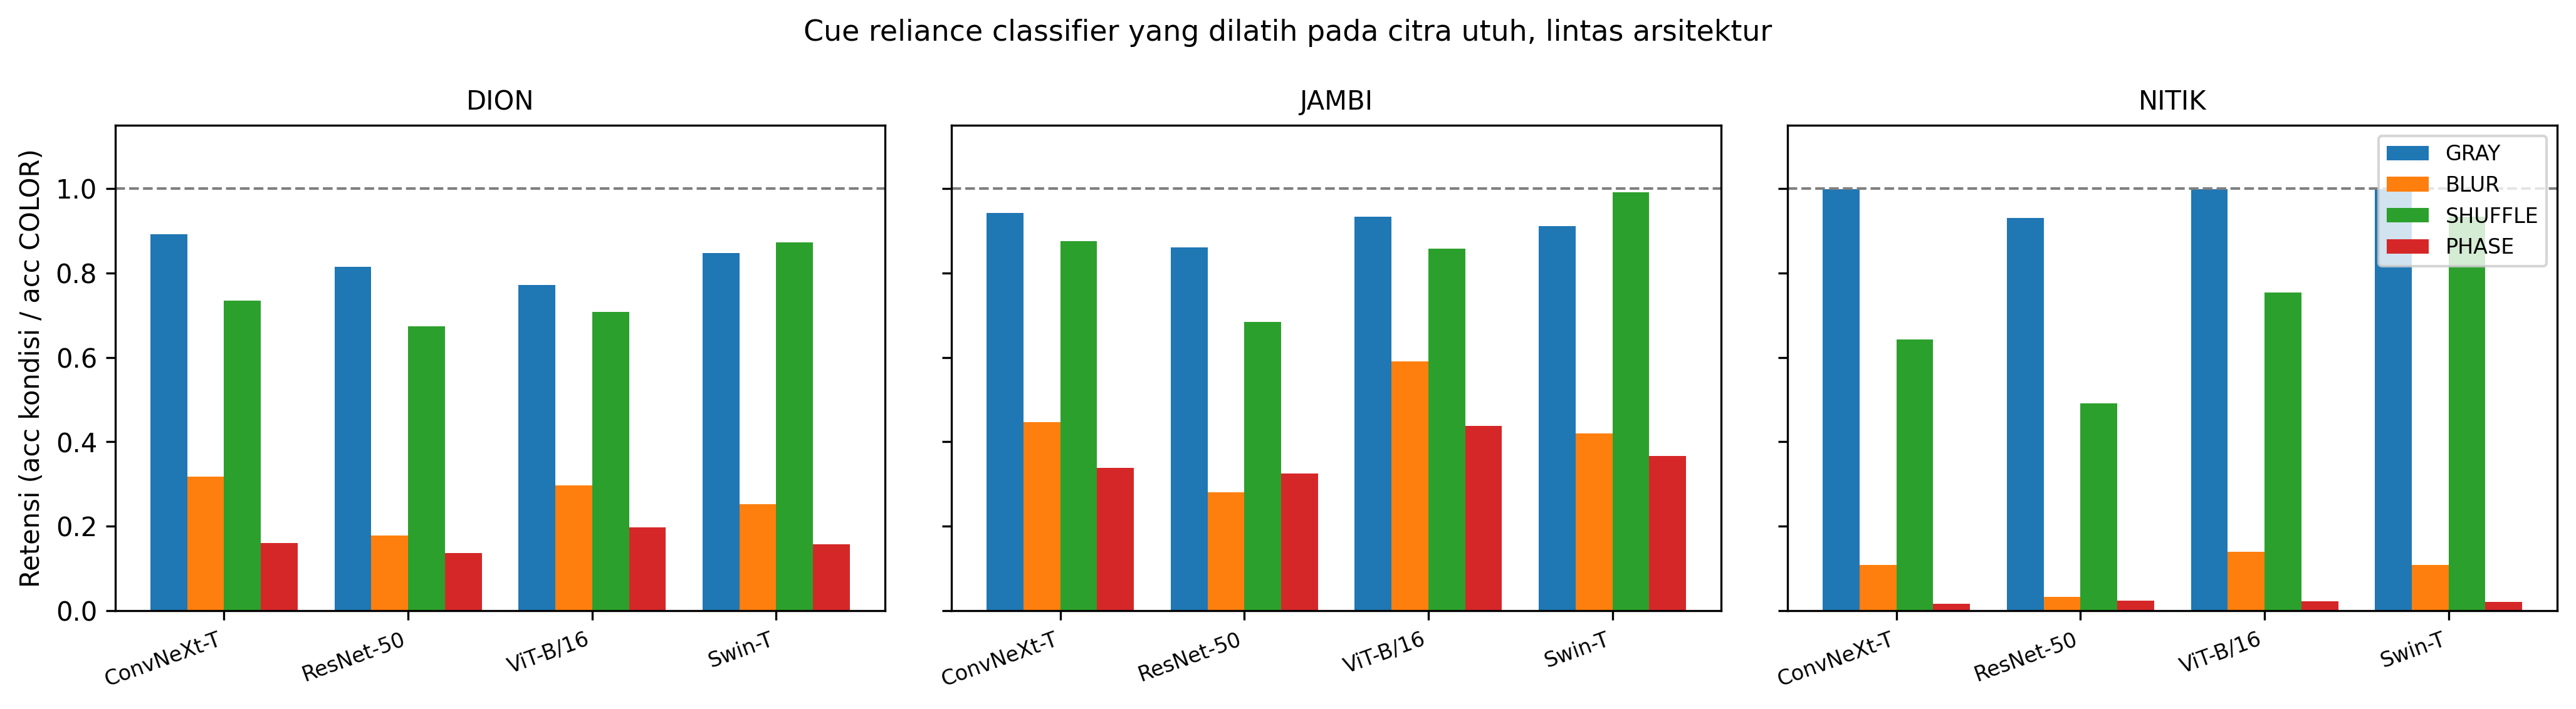

In [5]:
# ============================================================
# M5. Figure untuk paper: retensi per kondisi, dikelompokkan per arsitektur
# ============================================================
import matplotlib.pyplot as plt
summ=pd.read_csv("/kaggle/working/cue_reliance_multiarch_summary.csv")
show=["GRAY","BLUR","SHUFFLE","PHASE"]
dsets=sorted(summ.dataset.unique()); archs=[a for a in ARCHS if a in set(summ.arch)]

fig,axes=plt.subplots(1,len(dsets),figsize=(4.6*len(dsets),3.8),dpi=300,sharey=True)
if len(dsets)==1: axes=[axes]
w=0.8/len(show); x=np.arange(len(archs))
for ax,dname in zip(axes,dsets):
    sub=summ[summ.dataset==dname].set_index("arch")
    for i,c in enumerate(show):
        vals=[sub.loc[a,f"ret_{c}"] if a in sub.index else np.nan for a in archs]
        ax.bar(x+(i-(len(show)-1)/2)*w, vals, w, label=c)
    ax.axhline(1.0,ls="--",lw=1,color="grey")
    ax.set_xticks(x); ax.set_xticklabels(archs,rotation=20,ha="right",fontsize=8)
    ax.set_title(dname,fontsize=10); ax.set_ylim(0,1.15)
axes[0].set_ylabel("Retensi (acc kondisi / acc COLOR)")
axes[-1].legend(fontsize=8,loc="upper right")
fig.suptitle("Cue reliance classifier yang dilatih pada citra utuh, lintas arsitektur",fontsize=11)
plt.tight_layout()
plt.savefig("/kaggle/working/fig_cue_reliance_multiarch.png",dpi=300,bbox_inches="tight")
print("Tersimpan: fig_cue_reliance_multiarch.png")
plt.show()
